# MNIST CNN — Kaggle Notebook training (executed run)

This is the actual executed run, outputs intact — the reusable template lives at `kaggle_train_cnn.ipynb` in this folder, with the full Add Input / Settings walkthrough. Stretch-goal CNN comparison against the MLP results.

In [1]:
!pip install -q pytorch-lightning torchmetrics optuna python-dotenv

In [2]:
import sys

DATASET_DIR = '/kaggle/input/datasets/ivannamor/mnist-mlp-pipeline'
sys.path.insert(0, DATASET_DIR)
print('project code ready')

project code ready


In [3]:
from src.config import ExperimentConfig

config = ExperimentConfig.from_yaml(f'{DATASET_DIR}/configs/cnn_baseline.yaml')
config.data.data_dir = '/kaggle/input/competitions/digit-recognizer'
config.trainer.experiment_name = 'cnn_baseline'
config

ExperimentConfig(architecture='cnn', data=DataConfig(data_dir='/kaggle/input/competitions/digit-recognizer', train_csv='train.csv', val_fraction=0.2, test_fraction=0.2, batch_size=64, num_workers=2, seed=42), model=CNNModelConfig(conv_channels=[32, 64], kernel_size=3, activation='relu', dropout=0.25, fc_hidden_dim=128, num_classes=10), optim=OptimConfig(optimizer='adam', lr=0.001, weight_decay=0.0, label_smoothing=0.0, lr_scheduler=None), trainer=TrainerConfig(max_epochs=30, accelerator='auto', devices=1, patience=5, experiment_name='cnn_baseline'))

## Baseline CNN training run (GPU)

In [4]:
from src.train import train

trainer = train(config)

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                  ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net                   │ Sequential                │  421 K │ train │     0 │
│ 1 │ loss_fn               │ CrossEntropyLoss          │      0 │ train │     0 │
│ 2 │ val_accuracy          │ MulticlassAccuracy        │      0 │ train │     0 │
│ 3 │ val_precision         │ MulticlassPrecision       │      0 │ train │     0 │
│ 4 │ val_recall            │ MulticlassRecall          │      0 │ train │     0 │
│ 5 │ test_accuracy         │ MulticlassAccuracy        │      0 │ train │     0 │
│ 6 │ test_precision        │ MulticlassPrecision       │      0 │ train │     0 │
│ 7 │ test_recall           │ MulticlassRecall          │      0 │ train │     0 │
│ 8 │ test_confusion_matrix │ MulticlassConfusionMatrix │      0 │ train │     0 │
└───┴───────────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 421 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 421 K                                                                                                
Total estimated model params size (MB): 1.687                                                                      
Modules in train mode: 20                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

Best val_accuracy: 0.9871335625648499
Best checkpoint: outputs/logs/cnn_baseline/version_0/checkpoints/best.ckpt


## Hyperparameter search (Optuna)

Same `search.objective`/`search.build_config` as the MLP run — they dispatch on `config.architecture` (`'cnn'` here) to sample conv_channels/kernel_size/fc_hidden_dim instead of hidden_dims. No per-trial checkpoints (by design); the next cell retrains the winner for real.

In [5]:
import optuna
from src.search import objective

study = optuna.create_study(direction='maximize', pruner=optuna.pruners.MedianPruner())
study.optimize(lambda trial: objective(trial, config), n_trials=20)

print('Best value:', study.best_value)
print('Best params:', study.best_params)

[I 2026-08-01 18:00:00,992] A new study created in memory with name: no-name-b36c9a8b-b184-4d92-8359-3fea7b34dfdc
Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                  ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net                   │ Sequential                │  215 K │ train │     0 │
│ 1 │ loss_fn               │ CrossEntropyLoss          │      0 │ train │     0 │
│ 2 │ val_accuracy          │ MulticlassAccuracy        │      0 │ train │     0 │
│ 3 │ val_precision         │ MulticlassPrecision       │      0 │ train │     0 │
│ 4 │ val_recall            │ MulticlassRecall          │      0 │ train │     0 │
│ 5 │ test_accuracy         │ MulticlassAccuracy        │      0 │ train │     0 │
│ 6 │ test_precision        │ MulticlassPrecision       │      0 │ train │     0 │
│ 7 │ test_recall           │ MulticlassRecall          │      0 │ train │     0 │
│ 8 │ test_confusion_matrix │ MulticlassConfusionMatrix │      0 │ train │     0 │
└───┴───────────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 215 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 215 K                                                                                                
Total estimated model params size (MB): 0.861                                                                      
Modules in train mode: 20                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
[I 2026-08-01 18:00:27,078] Trial 0 finished with value: 0.9912184476852417 and parameters: {'conv_channels': 'narrow', 'kernel_size': 5, 'fc_hidden_dim': 128, 'activation': 'gelu', 'dropout': 0.43612158406158263, 'optimizer': 'adamw', 'lr': 0.006663440263293849, 'weight_decay': 0.00017267129465972907, 'label_smoothing': 0.1, 'batch_size': 256}. Best is trial 0 with value: 0.9912184476852417.
Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](ht

┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                  ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net                   │ Sequential                │  1.8 M │ train │     0 │
│ 1 │ loss_fn               │ CrossEntropyLoss          │      0 │ train │     0 │
│ 2 │ val_accuracy          │ MulticlassAccuracy        │      0 │ train │     0 │
│ 3 │ val_precision         │ MulticlassPrecision       │      0 │ train │     0 │
│ 4 │ val_recall            │ MulticlassRecall          │      0 │ train │     0 │
│ 5 │ test_accuracy         │ MulticlassAccuracy        │      0 │ train │     0 │
│ 6 │ test_precision        │ MulticlassPrecision       │      0 │ train │     0 │
│ 7 │ test_recall           │ MulticlassRecall          │      0 │ train │     0 │
│ 8 │ test_confusion_matrix │ MulticlassConfusionMatrix │      0 │ train │     0 │
└───┴───────────────────────┴───────────────────────────┴────────┴───────┴───────┘

...

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
`Trainer.fit` stopped: `max_epochs=30` reached.
[I 2026-08-01 18:26:58,809] Trial 18 finished with value: 0.9919403791427612 and parameters: {'conv_channels': 'wide', 'kernel_size': 3, 'fc_hidden_dim': 128, 'activation': 'gelu', 'dropout': 0.05672790277103301, 'optimizer': 'adam', 'lr': 0.00018647141630586035, 'weight_decay': 0.00010636017578831361, 'label_smoothing': 0.1, 'batch_size': 64}. Best is trial 18 with value: 0.9919403791427612.
Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploa

┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                  ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net                   │ Sequential                │  1.7 M │ train │     0 │
│ 1 │ loss_fn               │ CrossEntropyLoss          │      0 │ train │     0 │
│ 2 │ val_accuracy          │ MulticlassAccuracy        │      0 │ train │     0 │
│ 3 │ val_precision         │ MulticlassPrecision       │      0 │ train │     0 │
│ 4 │ val_recall            │ MulticlassRecall          │      0 │ train │     0 │
│ 5 │ test_accuracy         │ MulticlassAccuracy        │      0 │ train │     0 │
│ 6 │ test_precision        │ MulticlassPrecision       │      0 │ train │     0 │
│ 7 │ test_recall           │ MulticlassRecall          │      0 │ train │     0 │
│ 8 │ test_confusion_matrix │ MulticlassConfusionMatrix │      0 │ train │     0 │
└───┴───────────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 1.7 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.7 M                                                                                                
Total estimated model params size (MB): 6.732                                                                      
Modules in train mode: 20                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
`Trainer.fit` stopped: `max_epochs=30` reached.
[I 2026-08-01 18:28:47,822] Trial 19 finished with value: 0.9921683073043823 and parameters: {'conv_channels': 'wide', 'kernel_size': 3, 'fc_hidden_dim': 256, 'activation': 'gelu', 'dropout': 0.015026644895738628, 'optimizer': 'adam', 'lr': 0.00011324018558618522, 'weight_decay': 1.9867047025820187e-05, 'label_smoothing': 0.1, 'batch_size': 64}. Best is trial 19 with value: 0.9921683073043823.


Best value: 0.9921683073043823
Best params: {'conv_channels': 'wide', 'kernel_size': 3, 'fc_hidden_dim': 256, 'activation': 'gelu', 'dropout': 0.015026644895738628, 'optimizer': 'adam', 'lr': 0.00011324018558618522, 'weight_decay': 1.9867047025820187e-05, 'label_smoothing': 0.1, 'batch_size': 64}


## Retrain the winning configuration

In [6]:
from src.search import build_config

best_config = build_config(study.best_params, config)
best_config.trainer.experiment_name = 'cnn_best_from_search'
best_trainer = train(best_config)

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                  ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net                   │ Sequential                │  1.7 M │ train │     0 │
│ 1 │ loss_fn               │ CrossEntropyLoss          │      0 │ train │     0 │
│ 2 │ val_accuracy          │ MulticlassAccuracy        │      0 │ train │     0 │
│ 3 │ val_precision         │ MulticlassPrecision       │      0 │ train │     0 │
│ 4 │ val_recall            │ MulticlassRecall          │      0 │ train │     0 │
│ 5 │ test_accuracy         │ MulticlassAccuracy        │      0 │ train │     0 │
│ 6 │ test_precision        │ MulticlassPrecision       │      0 │ train │     0 │
│ 7 │ test_recall           │ MulticlassRecall          │      0 │ train │     0 │
│ 8 │ test_confusion_matrix │ MulticlassConfusionMatrix │      0 │ train │     0 │
└───┴───────────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 1.7 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.7 M                                                                                                
Total estimated model params size (MB): 6.732                                                                      
Modules in train mode: 20                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

`Trainer.fit` stopped: `max_epochs=30` reached.


Best val_accuracy: 0.9921683073043823
Best checkpoint: outputs/logs/cnn_best_from_search/version_0/checkpoints/best.ckpt


## Final test-set evaluation

Run once. Uses the same stratified test split as the MLP run (same seed, same data), so this is a fair, directly comparable number.

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test_accuracy       │    0.9921367168426514     │
│         test_loss         │    0.5313611030578613     │
│      test_precision       │    0.9922268390655518     │
│        test_recall        │    0.9921367168426514     │
└───────────────────────────┴───────────────────────────┘

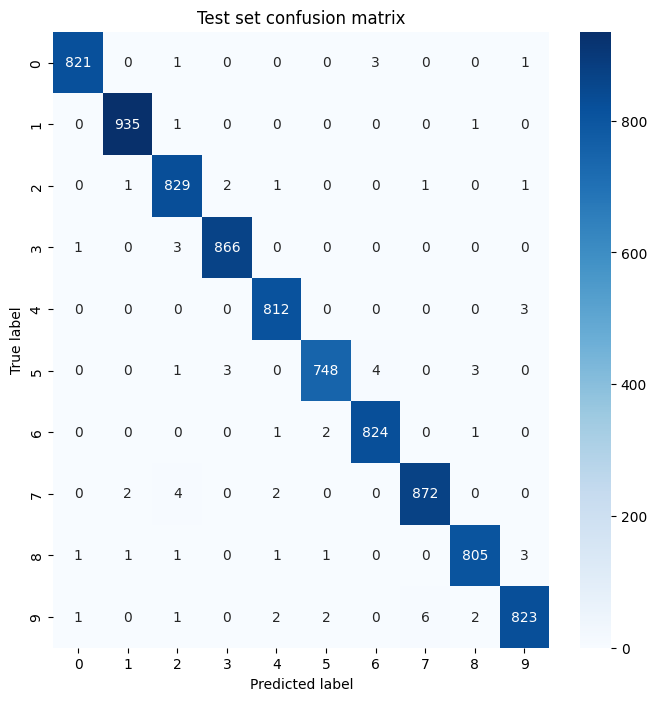

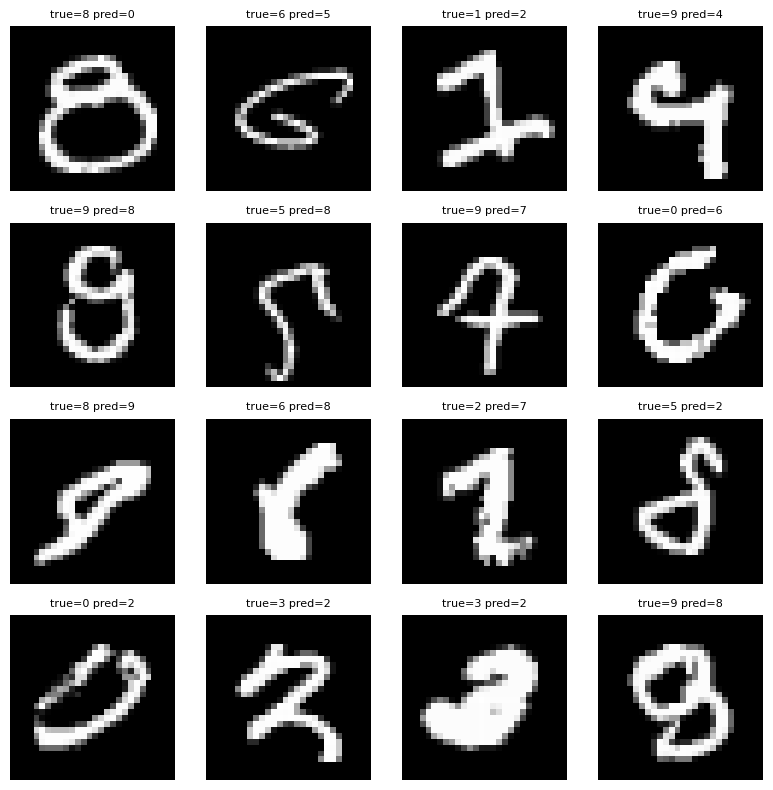

In [7]:
from pathlib import Path
from src.evaluate import evaluate

checkpoint_path = best_trainer.checkpoint_callback.best_model_path
evaluate(best_config, checkpoint_path, Path('/kaggle/working/evaluation'))

## Download results

Kaggle's `FileLink` 404'd for the MLP run's downloads — this base64 data-URI approach worked instead.

In [ ]:
import base64
from IPython.display import HTML, display

def make_download_link(path):
    filename = path.split('/')[-1]
    with open(path, 'rb') as f:
        data = base64.b64encode(f.read()).decode()
    return HTML(f'<a download="{filename}" href="data:application/octet-stream;base64,{data}">Download {filename}</a>')

display(make_download_link(checkpoint_path))
display(make_download_link('/kaggle/working/evaluation/confusion_matrix.png'))
display(make_download_link('/kaggle/working/evaluation/misclassified_examples.png'))